## How to add foreground contaminant to HI maps

We want to add the effect of foreground cleaning to our maps. The baseline workflow is at follows:
1. Take DM counts per redshift bin per pixel
2. Build number density contrast maps
3. Use them as line-of-sight redshift priors

### Now we want to see what would the effect of foreground contamination be
1. Take the Haslam map that provides the full sky map of diffuse synchrotron radiation in our Galaxy; we take the first file provided here [Desourced Destriped Haslam 408 MHz](https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_get.html);
2. Mask the galactic plane (10 deg above and below latitute zero)
3. Build the density contrast maps from Haslam map (with masked galactic plane)
4. Scatter the Haslam line-of-sight at different levels

### Inference with foreground contamination
At inference level use the line-of-sight redshift prior where the foreground contribution is summed to the HI one (for the pixels in the galactic plane use just the uniform in comoving volume prior)

In [1]:
import numpy as np
import pandas as pd
import os
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from astropy.io import fits

from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

import os
os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"

# Your custom text color
mycolor = 'black'  # or e.g., '#fe9463', (0.996, 0.580, 0.388)
from matplotlib import rcParams
# Global style settings
rcParams.update({
    # Enable LaTeX rendering
    'text.usetex': True,

    # Font settings
    'font.family': 'sans-serif',
    'font.sans-serif': ['Open Sans'],  # Use Open Sans if available

    # Set all text and visual elements to use the custom color
    'text.color': mycolor,
    'axes.labelcolor': mycolor,
    'xtick.color': mycolor,
    'ytick.color': mycolor,
    'axes.edgecolor': mycolor,
    'grid.color': mycolor,
    'legend.edgecolor': mycolor,
    'legend.facecolor': 'none',
    'legend.labelcolor': mycolor,

    # Transparent backgrounds
    'figure.facecolor': 'none',
    'axes.facecolor': 'none',
})

if mycolor=='white':
    rcParams['savefig.transparent'] = True

import matplotlib as mpl
mpl.rcParams['figure.facecolor'] = 'none'
mpl.rcParams['axes.facecolor']   = 'none'
mpl.rcParams['savefig.facecolor'] = 'none'
# fix tick labels size
mpl.rcParams['xtick.labelsize'] = 18
mpl.rcParams['ytick.labelsize'] = 18
mpl.rcParams['axes.labelsize'] = 18
mpl.rcParams['legend.fontsize'] = 18
mpl.rcParams['axes.titlesize'] = 18

In [2]:
nside_dm=128 # original dm maps resolution
npix_dm=hp.nside2npix(nside_dm)
nside_output = 16
npix_output  = hp.nside2npix(nside_output)
lmax         = nside_output * 3

## Haslam map at 408 MHz (reference: https://arxiv.org/pdf/1411.3628)
It provides a map of the large-scale diffuse Galactic synchrotron emission.

In [3]:
user = 'ulyana.dupletsa'
PATH_TO_HASLAM_MAP = '/Users/' + str(user) + '/Documents/Radio-Sirens/foreground_data/'
# I use the first file provided here (https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_get.html)
# It says Desources Destriped Haslam 408 MHz
haslam_map = 'haslam408_dsds_Remazeilles2014.fits'

In [4]:
with fits.open(PATH_TO_HASLAM_MAP + haslam_map) as hdul:
    header = hdul[1].header  

    print("Column:", header["TTYPE1"])  # TEMPERATURE
    print("Units:", header["TUNIT1"])   # K
    print(hdul[1].columns)             # All column names and units

Column: TEMPERATURE
Units: K
ColDefs(
    name = 'TEMPERATURE'; format = '1024E'; unit = 'K'
)


In [5]:
# Read the temperature column into a 1D array of HEALPix pixels.
haslam_map_in = hp.read_map(PATH_TO_HASLAM_MAP + haslam_map, field=0, nest=False)
nside_fg = hp.get_nside(haslam_map_in)
print('The original nside of Haslam map is: ', nside_fg)
# Downgrade the Haslam map to the same nside as target HI maps
haslam_map_out = hp.ud_grade(
    haslam_map_in,
    nside_out=nside_output,
    order_in="RING",
    order_out="RING",
    power=0,
)


The original nside of Haslam map is:  512


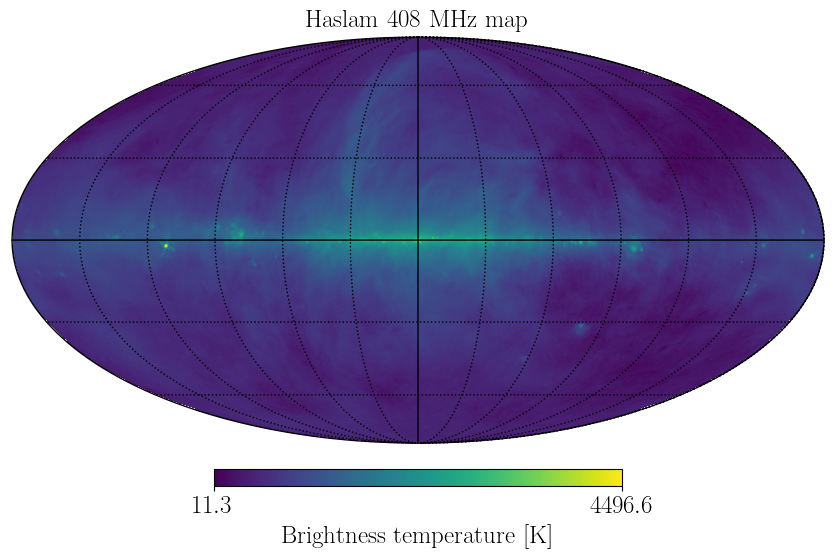

In [6]:
# Plot the full sky in a Mollweide projection (ORIGINAL MAP)
hp.mollview(
    haslam_map_in,
    nest=False,
    title=r"\rm Haslam 408 MHz map",
    cmap="viridis",
    norm="log",
)
hp.graticule(dpar=30, dmer=30)
# Get the current figure and axes
fig = plt.gcf()
cbar_ax = fig.axes[-1]
cbar_ax.tick_params(labelsize=18)
cbar_ax.set_xlabel(r'\rm Brightness temperature [K]', fontsize=18)
cbar_ax.xaxis.set_major_formatter(FormatStrFormatter(r'$%.1f$'))
plt.show()

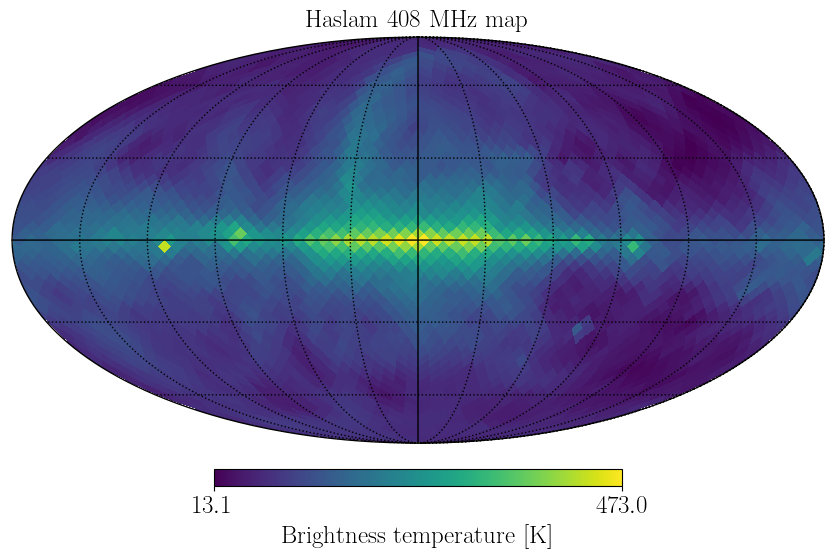

In [7]:
# Plot the full sky in a Mollweide projection (reduced nside)
hp.mollview(
    haslam_map_out,
    nest=False,
    title=r"\rm Haslam 408 MHz map",
    cmap="viridis",
    norm="log",
)
hp.graticule(dpar=30, dmer=30)
# Get the current figure and axes
fig = plt.gcf()
cbar_ax = fig.axes[-1]
cbar_ax.tick_params(labelsize=18)
cbar_ax.set_xlabel(r'\rm Brightness temperature [K]', fontsize=18)
cbar_ax.xaxis.set_major_formatter(FormatStrFormatter(r'$%.1f$'))
plt.show()

In [8]:
LATITUDE_CUT_DEG = 10.0  # An analysis choice; test sensitivity to larger cuts.

def galactic_valid_pixels(map_in):
    """Valid pixels for maps already in Galactic coordinates, RING ordering."""
    values = np.asarray(np.ma.getdata(map_in), dtype=float)
    _, latitude = hp.pix2ang(hp.get_nside(values), np.arange(values.size),
                            nest=False, lonlat=True)
    return (np.isfinite(values) & ~hp.mask_bad(values)
            & ~np.ma.getmaskarray(map_in)
            & (np.abs(latitude) >= LATITUDE_CUT_DEG))

def remove_galactic_plane(map_in):
    # Zero is a neutral contrast for calculations, NOT a mask identifier.
    return np.where(galactic_valid_pixels(map_in), map_in, 0.0)

In [9]:
haslam_mean_per_pix = np.mean(haslam_map_out)
haslam_contrast_map = (haslam_map_out - haslam_mean_per_pix) / haslam_mean_per_pix
masked_haslam_map = remove_galactic_plane(haslam_contrast_map)

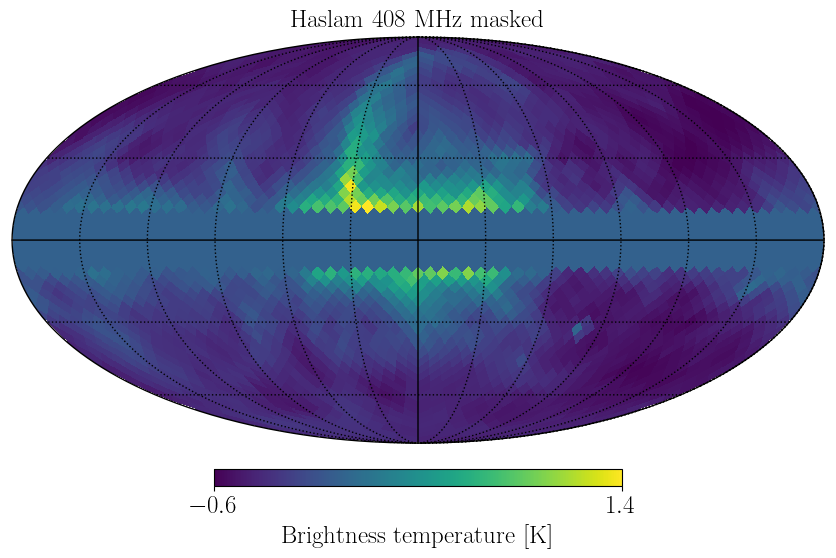

In [11]:
masked_map = remove_galactic_plane(masked_haslam_map)

hp.mollview(
    masked_map,
    title=r"\rm Haslam 408 MHz masked",
    norm=None,
    cmap="viridis",
    badcolor="lightgray",
)
hp.graticule(dpar=30, dmer=30)
# Get the current figure and axes
fig = plt.gcf()
cbar_ax = fig.axes[-1]
cbar_ax.tick_params(labelsize=18)
cbar_ax.set_xlabel(r'\rm Brightness temperature [K]', fontsize=18)
cbar_ax.xaxis.set_major_formatter(FormatStrFormatter(r'$%.1f$'))
plt.show()

## Apply foreground residual contamination to HI maps

In [12]:
PATH_TO_MAPS = '/Users/' + str(user) + '/Documents/Radio-Sirens/dm_halos_data/count_maps/'

In [13]:
count_data = {}
count_map = {}
count_map_out = {}
mean_count_per_pix = {}
zmean_vec = []

np.random.seed(42)
for file in os.listdir(PATH_TO_MAPS):
    # strip string to get the redshit range out of the name of the map
    if file == "README.md":
        continue
    else:
        name_strips = file.split('_')
        snapshot, zmin, zmax, nside_ov = name_strips[2][8:10], name_strips[3][4:8], name_strips[4][4:8], name_strips[5][5:8]
        # consider the mean value of the redshift range for each snapshot
        zmean = np.round((float(zmin) + float(zmax))/2, 3)
        zmean_vec.append(zmean)
        count_data[str(zmean)] = np.loadtxt(PATH_TO_MAPS + file)
        # REMEMBER TO USE THE ORIGINAL PIXELIZATION
        npix = hp.nside2npix(int(nside_ov))
        mean_count_per_pix[str(zmean)] = np.sum(count_data[str(zmean)])/npix
        # build number density contrast maps
        count_map[str(zmean)] = (count_data[str(zmean)] - mean_count_per_pix[str(zmean)])/mean_count_per_pix[str(zmean)]
        # downgrade the map to the desired nside (default is from 128 to 16)
        count_map_out[str(zmean)] = hp.ud_grade(count_map[str(zmean)], nside_out=nside_output)

In [14]:
# scatter the Haslam map for each pixel
# pixel per pixel
scattered_los_haslam = {}
for i in range(npix_output):   
    if masked_haslam_map[i] == 0.:
        scattered_los_haslam[i] = np.zeros_like(zmean_vec)
    else:
        scattered_los_haslam[i] = np.random.normal(masked_haslam_map[i], np.sqrt(np.abs(masked_haslam_map[i])), len(zmean_vec))

In [15]:
zmean_vec = np.array(zmean_vec)
zmean_vec = np.sort(zmean_vec)

In [16]:
masked_count_map_out = {}
for z_value in zmean_vec:
    masked_count_map_out[str(z_value)] = remove_galactic_plane(count_map_out[str(z_value)])
masked_count_map_out_df = pd.DataFrame(masked_count_map_out).sort_index(axis=1)

[-0.08066553 -0.08608403 -0.08214529 -0.02297194 -0.08131718 -0.03046169
  0.0973015   0.01113443 -0.07452264  0.03475262 -0.08039353 -0.19702506
 -0.12332487 -0.18505225 -0.07634647 -0.0498775   0.06875529 -0.0278034
 -0.0668722   0.00814939 -0.20940414 -0.03433691  0.00396077 -0.15698957
  0.03064131 -0.02697562 -0.08090959 -0.00591922  0.11127483 -0.03818265
 -0.03343494 -0.08406305 -0.11200251  0.00821595 -0.11244895 -0.04607472
 -0.08537219]


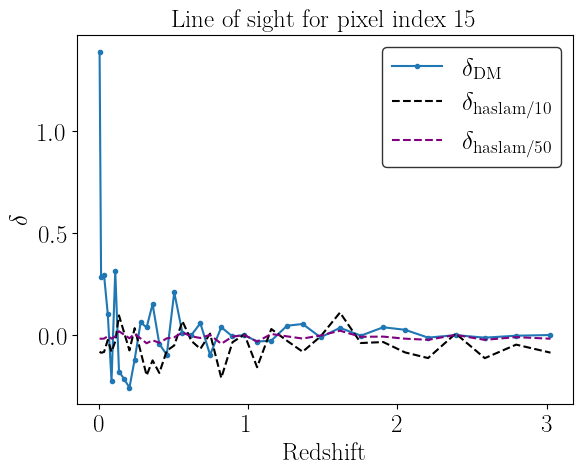

In [18]:
pixel_index = 15
print(scattered_los_haslam[pixel_index]/10)
plt.plot(zmean_vec, masked_count_map_out_df.loc[pixel_index], marker='.', color='tab:blue', label=r'\rm $\delta_{\rm DM}$')
plt.plot(zmean_vec, scattered_los_haslam[pixel_index]/10, color='black', linestyle='dashed', label=r'\rm $\delta_{\rm haslam/10}$')
plt.plot(zmean_vec, scattered_los_haslam[pixel_index]/50, color='purple', linestyle='dashed', label=r'\rm $\delta_{\rm haslam/50}$')
plt.xlabel(r'\rm Redshift')
plt.ylabel(r'\rm $\delta$')
plt.title(rf'\rm Line of sight for pixel index {pixel_index}')
plt.legend()
plt.show()

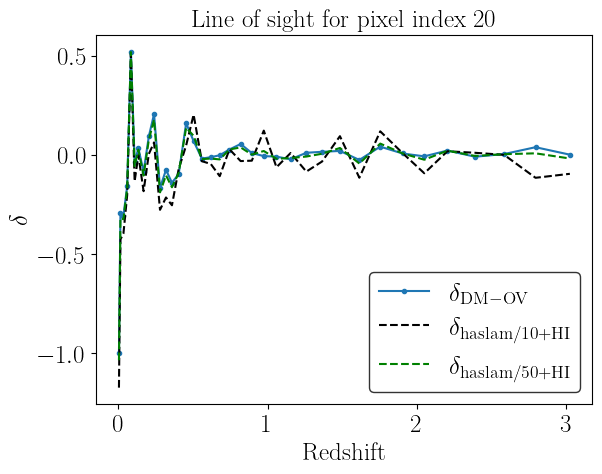

In [20]:
pixel_index = 20
plt.plot(zmean_vec, masked_count_map_out_df.loc[pixel_index], marker='.', color='tab:blue', label=r'\rm $\delta_{\rm DM - OV}$')
plt.plot(zmean_vec, scattered_los_haslam[pixel_index]/10 + masked_count_map_out_df.loc[pixel_index], color='black', linestyle='dashed', label=r'\rm $\delta_{\rm haslam/10 + HI}$')
plt.plot(zmean_vec, scattered_los_haslam[pixel_index]/50 + masked_count_map_out_df.loc[pixel_index], color='green', linestyle='dashed', label=r'\rm $\delta_{\rm haslam/50 + HI}$')
plt.xlabel(r'\rm Redshift')
plt.ylabel(r'\rm $\delta$')
plt.title(rf'\rm Line of sight for pixel index {pixel_index}')
plt.legend()
plt.show()

In [ ]:
scattered_los_haslam_df = pd.DataFrame(scattered_los_haslam, index=zmean_vec)

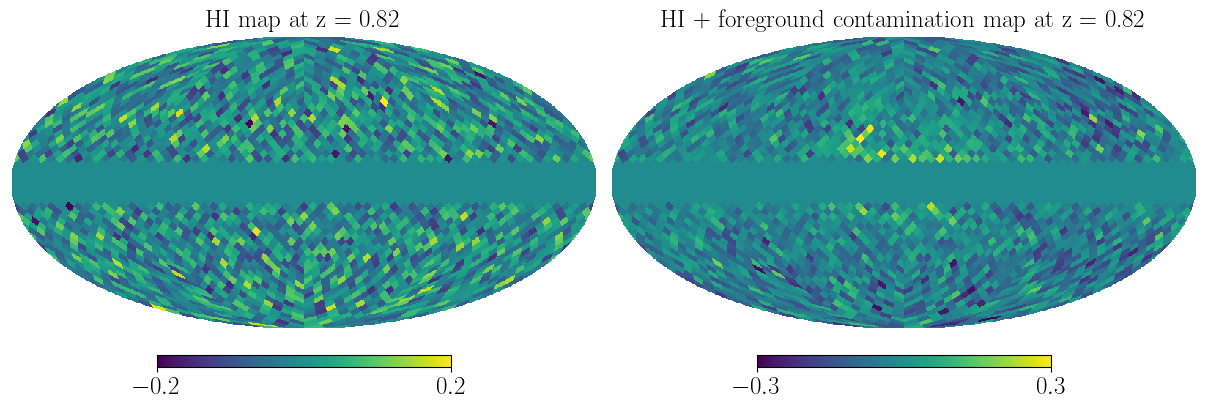

In [22]:
fig = plt.figure(figsize=(12, 5))
zbin = 20
hp.mollview(
    masked_count_map_out[str(zmean_vec[zbin])],
    nest=False,
    title=r"\rm HI map at z = %s" %zmean_vec[zbin],
    cmap="viridis",  fig=fig.number, sub=(1, 2, 1))
hp.mollview(
    masked_count_map_out[str(zmean_vec[zbin])] + scattered_los_haslam_df.loc[zmean_vec[zbin]]/10,
    nest=False,
    title=r"\rm HI  + foreground contamination map at z = %s" %zmean_vec[zbin],
    cmap="viridis",  fig=fig.number, sub=(1, 2, 2))
fig = plt.gcf()
cbar_axs = fig.axes
for cbar_ax in cbar_axs:
    cbar_ax.tick_params(labelsize=18)
    cbar_ax.xaxis.set_major_formatter(FormatStrFormatter(r'$%.1f$'))
plt.show()

In [32]:
icaro_map_medium_contamination = np.zeros((len(zmean_vec), npix_output))
icaro_map_high_contamination = np.zeros((len(zmean_vec), npix_output))
icaro_map_no_galactic_plane = np.zeros((len(zmean_vec), npix_output))
for i, redshift_value in enumerate(zmean_vec):
    # add 1 to the number density contrast map to get the number density map, and store it in the 3D array
    # this quantity represent 1 + delta = n/nbar, where n is the number density in each pixel and nbar is the mean number density across the sky
    icaro_map_medium_contamination[i] = 1 + np.array(masked_count_map_out[str(zmean_vec[i])] + scattered_los_haslam_df.loc[zmean_vec[i]]/50)
    icaro_map_high_contamination[i] = 1 + np.array(masked_count_map_out[str(zmean_vec[i])] + scattered_los_haslam_df.loc[zmean_vec[i]]/10)
    icaro_map_no_galactic_plane [i] = 1 + np.array(masked_count_map_out[str(zmean_vec[i])])

icaro_df_medium_fg = pd.DataFrame(icaro_map_medium_contamination)
icaro_df_high_fg = pd.DataFrame(icaro_map_high_contamination)
icaro_df_no_galactic_plane = pd.DataFrame(icaro_map_no_galactic_plane)

In [34]:
# global min and max values of the map
icaro_df_medium_fg.min().min(), icaro_df_medium_fg.max().max(), icaro_df_high_fg.min().min(), icaro_df_high_fg.max().max(), icaro_df_no_galactic_plane.min().min(), icaro_df_no_galactic_plane.max().max()

(-0.047705073348602856,
 14.346632572799443,
 -0.23852536674301472,
 14.33495344398943,
 0.0,
 14.349552355001947)

In [35]:
# where icaro_df == 0 replace with a small value to avoid issues with log(0) in the icarogw code
icaro_df_medium_fg[icaro_df_medium_fg <= 0] = 1e-5
icaro_df_high_fg[icaro_df_high_fg <= 0] = 1e-5
icaro_df_no_galactic_plane[icaro_df_no_galactic_plane <= 0] = 1e-5

In [36]:
# global min and max values of the map
icaro_df_medium_fg.min().min(), icaro_df_medium_fg.max().max(), icaro_df_high_fg.min().min(), icaro_df_high_fg.max().max()

(1e-05, 14.346632572799443, 1e-05, 14.33495344398943)

In [37]:
icaro_df_medium_fg.to_hdf('hi_data/map4icaro_lmax%s_zmin%s_zmax%s_nside%s_medium_fg.hdf5' %(lmax,zmean_vec[0],zmean_vec[-1],nside_output), key='df', mode='w')
icaro_df_high_fg.to_hdf('hi_data/map4icaro_lmax%s_zmin%s_zmax%s_nside%s_high_fg.hdf5' %(lmax,zmean_vec[0],zmean_vec[-1],nside_output), key='df', mode='w')
icaro_df_no_galactic_plane.to_hdf('hi_data/map4icaro_lmax%s_zmin%s_zmax%s_nside%s_no_galactic_plane.hdf5' %(lmax,zmean_vec[0],zmean_vec[-1],nside_output), key='df', mode='w')

In [ ]:
#original map for comparison
icaro_df = pd.read_hdf('hi_data/map4icaro_lmax' + str(lmax) + '_zmin' + str(zmean_vec[0]) + '_zmax' + str(zmean_vec[-1]) + '_nside' + str(nside_output) + '.hdf5')

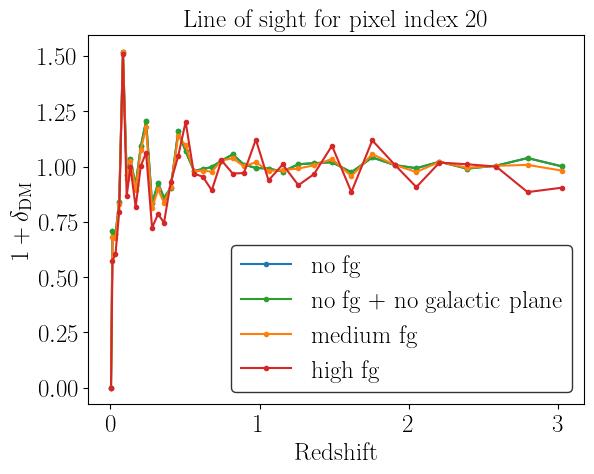

In [40]:
# plot the 1 + delta quantity for a given line of sight (i.e. a given pixel) as a function of redshift
pixel_index = 20
plt.plot(zmean_vec, icaro_df[pixel_index], marker='.', color='tab:blue', label=r'\rm no fg')
plt.plot(zmean_vec, icaro_df_no_galactic_plane[pixel_index], marker='.', color='tab:green', label=r'\rm no fg + no galactic plane')
plt.plot(zmean_vec, icaro_df_medium_fg[pixel_index], marker='.', color='tab:orange', label=r'\rm medium fg')
plt.plot(zmean_vec, icaro_df_high_fg[pixel_index], marker='.', color='tab:red', label=r'\rm high fg')
plt.xlabel(r'\rm Redshift')
plt.ylabel(r'\rm $1 + \delta_{\rm DM}$')
plt.legend()
plt.title(rf'\rm Line of sight for pixel index {pixel_index}')
plt.show()

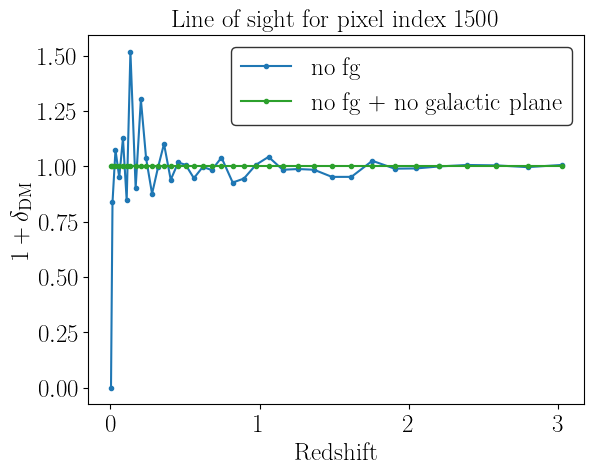

In [ ]:
# plot the 1 + delta quantity for a given line of sight (i.e. a given pixel) as a function of redshift
pixel_index = 1500 # choose a pixel that is masked by the galactic plane
plt.plot(zmean_vec, icaro_df[pixel_index], marker='.', color='tab:blue', label=r'\rm no fg')
plt.plot(zmean_vec, icaro_df_no_galactic_plane[pixel_index], marker='.', color='tab:green', label=r'\rm no fg + no galactic plane')
#plt.plot(zmean_vec, icaro_df_medium_fg[pixel_index], marker='.', color='tab:orange', label=r'\rm medium fg')
#plt.plot(zmean_vec, icaro_df_high_fg[pixel_index], marker='.', color='tab:red', label=r'\rm high fg')
plt.xlabel(r'\rm Redshift')
plt.ylabel(r'\rm $1 + \delta_{\rm DM}$')
plt.legend()
plt.title(rf'\rm Line of sight for pixel index {pixel_index}')
plt.show()